In [43]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [27]:
import pandas as pd
import os
import glob
import shutil
import geopandas as gpd

import xarray as xr
import numpy as np
from pyhomogenize import open_xrdataset
import seaborn as sns
#
import matplotlib as mpl
import matplotlib.pyplot as plt
import cftime
import xesmf as xe
import cordex as cx

In [28]:
from colors_indices import colorsteps_comp_ev
#from colors_indices import colorsteps_diff, colorsteps_absolute, colorsteps_exposure
from plotting_tools_africa import plot_absolut, plot_era
from plotting_shape_file import min_max_levels, mask_and_save, maskout_country_era5
from regrid_afr22 import regrid_ensemble_median

In [29]:
# The data needs to be regridded to the AFR-22 domain.
# Target Grid::
dm=cx.cordex_domain('AFR-22', bounds=True)

In [30]:
# Directory input data, calculated compound events
datadir='/work/ch0636/g300047/cicles/compound-events/results-era5'


In [31]:
# Input shapefile:
# Admin regions
# select country and correct shape file
country='Burkina_Faso'
country_short='BF'

adm_reg_dir='/work/ch0636/g300047/cicles/regions/WASCAL/WASCAL_Country'
admfiles = ['Togo.shp', "Côte d'Ivoire.shp",'Burkina Faso.shp']

# Select admit files
adm_shapefile =os.path.join(adm_reg_dir, admfiles[2])
shpfile_country=gpd.read_file(adm_shapefile)


In [37]:
plot_options_era5 = {
	"SU40_du3_TR26_du3": "Concurrent heat days (Tmax>40°C, ≥3 days)\nand tropical nights (Tmin>26°C, ≥3 days)",
	"SU35_du3_DD_du5": "Concurrent heat days (Tmax>35°C, ≥3 days)\nand dry days [RR<1mm/day, ≥5 days]",
	"SU35_du3_R20mm_du1": "Concurrent heat days (Tmax>35°C, ≥3 days)\nand heavy precipitation events [RR>20mm/day, ≥1 day]",
	"SU40_du3_DD_du5": "Concurrent heat days (Tmax>40°C, ≥3 days)\nand dry days [RR<1mm/day, ≥5 days]",
	"SU40_du3_R20mm_du1": "Concurrent heat days (Tmax>40°C, ≥3 days)\nand heavy precipitation events [RR>20mm/day, ≥1 day]",
	"SU40_du3_TR_du3": "Concurrent heat days (Tmax>40°C, ≥3 days)\nand tropical nights [Tmin>20°C, ≥3 days]",
	"SU40_du3_R50mm_du1": "Concurrent heat days (Tmax>40°C, ≥3 days)\nand heavy precipitation events [RR>50mm/day, ≥1 day]",
	"SU35_du7_DD_du7": "Concurrent heat days (Tmax>35°C, ≥7 days)\nand dry days [RR<1mm/day, ≥7 days]",
	"DD_du7_R20mm_du1": "Concurrent dry days [RR<1mm/day, ≥7 days]\nand heavy precipitation events [RR>20mm/day, ≥1 day]",
	"SU40_du7_DD_du7": "Concurrent heat days (Tmax>40°C, ≥7 days)\nand dry days [RR<1mm/day, ≥7 days]",
}

var_pattern = "SU40_du3_TR26_du3"
#var_pattern = "SU35_du3_DD_du5"
#var_pattern = "SU35_du3_R20mm_du1"
#var_pattern = "SU40_du3_DD_du5"
#var_pattern = "SU40_du3_R20mm_du1"
##var_pattern = "SU40_du3_TR_du3"
#var_pattern = "SU40_du3_R50mm_du1"
#var_pattern = "SU35_du7_DD_du7"
#var_pattern = "SU40_du7_DD_du7"
#var_pattern = "DD_du7_R20mm_du1"

if var_pattern not in plot_options_era5:
	raise ValueError(f"Unknown var_pattern: {var_pattern}. Available: {list(plot_options_era5.keys())}")

title = plot_options_era5[var_pattern]
print(f"Selected var_pattern: {var_pattern}")

Selected var_pattern: SU40_du3_TR26_du3


In [33]:
simera5 = glob.glob(datadir+'/compev_'+var_pattern+'_1991-2020.nc')
print(datadir)
# Sort the files to ensure correct order
#simera5 = sorted(simera5)

simera5

/work/ch0636/g300047/cicles/compound-events/results-era5


['/work/ch0636/g300047/cicles/compound-events/results-era5/compev_SU40_du3_TR26_du3_1991-2020.nc']

In [ ]:
# plot
plot_dir='/work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_compound_events_era5'
os.makedirs(plot_dir, exist_ok=True)
var='ev_coin_sdu'

# mask out only country
simera5_masked = maskout_country_era5(
    simera5,
    shpfile_country,
    dm,
    var,
    datadir,
    country_short
)

Masked files saved:
ev_coin_sdu 1991-2020: ['/work/ch0636/g300047/cicles/compound-events/results-era5/masked/compev_SU40_du3_TR26_du3_1991-2020_BF_masked_country.nc']


In [50]:
# Recalculate levels based on masked data
print('Selected colors, levels for plotting ', var)
color_steps, level_steps = colorsteps_comp_ev(var,var_pattern)

#level_steps = min_max_levels(simera5, simera5_masked, var)

Selected colors, levels for plotting  ev_coin_sdu


In [46]:
var_pattern, var

('SU40_du3_TR26_du3', 'ev_coin_sdu')

plotting data from: ['/work/ch0636/g300047/cicles/compound-events/results-era5/masked/compev_SU40_du3_TR26_du3_1991-2020_BF_masked_country.nc']
shapefile provided:
adding borders from shapefile
/work/ch0636/g300047/cicles/compound-events/results-era5/masked/compev_SU40_du3_TR26_du3_1991-2020_BF_masked_country.nc


/home/g/g300047/SCRIPTS/github/factsheet_africa/Notebooks/HORIZONTAL/plotting_tools_africa.py:808: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  


file is here: /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_compound_events_era5/ev_coin_sdu_absolut_Burkina_Faso_1200.png


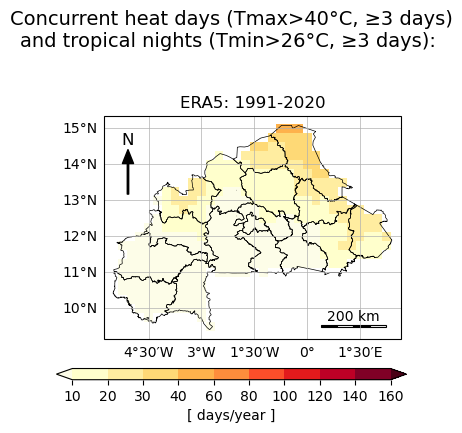

In [63]:

# Restore the plotting box using the existing variables and plot_era
plot_era(
    simera5_masked,
    level_steps,
    color_steps,
    plot_dir,
    title=title,
    var=var,
    westafrica=True,
    shapefile=shpfile_country,
    country=country,
    user_dpi=1200,
    rows=1,
    columns=1,
    fancy=True,
)
 #   row_gap=-0.05,
 #   wspace=0.25
#)